# Etapa 02: La base real del laboratorio

Esta etapa trabaja la base real del proyecto: La exportación del laboratorio que consiguió Daniel Arias Mutis (con
los clientes anonimizados). Los notebooks 01 y 03 a 06 la complementan con una base simulada de la misma estructura
para aplicar más técnicas del curso y aquí trabajamos con los datos reales. Daniel trabaja en el laboratorio y nos
propuso dos cosas: Clasificar a los clientes por su volumen semanal o mensual y a los lotes por su tamaño. Además
nos dijo que las llegadas de muestras le sonaban a un proceso de Poisson. Esta etapa cuenta qué pasó cuando pusimos
a prueba esa idea.

Dos reglas de entrada. La primera es que usamos solo fechas de desarrollo: Todo lo que ingresó desde el corte de
prueba (es decir 2026) se queda por fuera de cada cuenta hasta la sección 7, donde lo abrimos una sola vez para
evaluar el clasificador ya congelado. Así no gastamos antes de tiempo un periodo que nadie ha mirado. La segunda es
que el archivo es confidencial y no viaja con el proyecto así que si no está (por ejemplo en Colab) cada sección
muestra una nota en vez de cifras.

← Anterior: [Etapa 01: Datos y exploración](01_datos_exploracion.ipynb)<br>[Notebook completo](Proyecto_Final.ipynb)<br>Siguiente: [Etapa 03: Cribado y regresión](03_cribado_regresion.ipynb) →

## Código del proyecto

La celda siguiente prepara el código del proyecto. En una copia del repositorio no hace nada y en Google Colab trae el paquete `proyecto/` desde `notebooks/codigo/` (si se subió junto al notebook) o desde el repositorio, así que basta con ejecutar todo (*Entorno de ejecución → Ejecutar todas*). La sección se puede plegar desde su título. Trae también los guiones de las etapas anteriores: Si sus resultados no están en la sesión, la etapa los vuelve a calcular en silencio antes de empezar.

In [ ]:
# Código del proyecto (68 archivos, 218 kB): el paquete proyecto/ (56 módulos) y el mapeo de columnas, los guiones de las 1 etapas previas.
# En una copia del repositorio o en la carpeta de la entrega ya está y no se toca nada.
# En Colab se extrae de codigo/02_base_real.tar.xz si se subió junto al notebook o se descarga
# del repositorio; en los dos casos se comprueba su huella SHA-256 antes de extraerlo.
# Un archivo local con otro contenido se conserva (SOBRESCRIBIR = True lo reemplaza).
import hashlib, importlib, io, os, sys, tarfile, urllib.request
from pathlib import Path

ARCHIVO, HUELLA, SOBRESCRIBIR = "02_base_real.tar.xz", "533fbfba35f744c0fb1187c849409a6a75a2fc9708ad4c82c0cd3f5056b5a66d", False
URL = "https://raw.githubusercontent.com/Over-HCV/ML-I/main/content/docs/final-project/notebooks/codigo/" + ARCHIVO

if Path.cwd().name == "notebooks" and Path("../proyecto/__init__.py").exists():
    os.chdir("..")  # abierto desde notebooks/: se trabaja en la raíz del proyecto


def recrear_proyecto():
    origen = next((Path(d) / ARCHIVO for d in ("notebooks/codigo", "codigo", ".") if (Path(d) / ARCHIVO).exists()), None)
    if origen is None and Path("proyecto/__init__.py").exists():
        escritos, iguales, conservados = 0, None, []
    else:
        datos = origen.read_bytes() if origen else urllib.request.urlopen(URL, timeout=60).read()
        if hashlib.sha256(datos).hexdigest() != HUELLA:
            raise ValueError(f"{ARCHIVO} no corresponde a este notebook: su SHA-256 no coincide.")
        escritos, iguales, conservados = 0, 0, []
        with tarfile.open(fileobj=io.BytesIO(datos), mode="r:xz") as archivo:
            for miembro in archivo.getmembers():
                destino = Path(miembro.name)
                if destino.is_absolute() or ".." in destino.parts:
                    raise ValueError(f"Ruta no permitida en el archivo: {miembro.name}")
                contenido = archivo.extractfile(miembro).read()
                if destino.exists() and destino.read_bytes() == contenido:
                    iguales += 1
                elif destino.exists() and not SOBRESCRIBIR:
                    conservados.append(miembro.name)
                else:
                    destino.parent.mkdir(parents=True, exist_ok=True)
                    destino.write_bytes(contenido)
                    escritos += 1
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())
    importlib.invalidate_caches()
    print("Código del proyecto:", "se usa la copia local." if iguales is None
          else f"{escritos} archivos escritos, {iguales} ya estaban iguales.")
    if conservados:
        print(f"Se conservaron {len(conservados)} archivos locales distintos:", ", ".join(conservados))


recrear_proyecto()

## Desarrollo de la etapa

In [1]:
from proyecto.base.artefactos import iniciar_etapa
from proyecto.base.salida import mostrar
from proyecto.etapas import datos_reales

iniciar_etapa("02_base_real")
c = datos_reales.iniciar()
mostrar(c.encabezado)

## 1. La base real

La exportación no viene con una fila por muestra. Trae una fila por cada muestra, especificación y lectura así que
una muestra con seis especificaciones y un reanálisis ocupa siete u ocho filas. Lo primero que hicimos fue volver a
una fila por muestra y después agrupar las muestras en **lotes**. Un lote son las muestras que un mismo cliente
ingresa el mismo día y del mismo tipo: **Producto** (producto terminado, materia prima, agua, granel o envase) o
**planta** (superficies, ambientes y personal que el laboratorio recoge en un muestreo en la planta del cliente).

In [2]:
datos_reales.la_base(c).mostrar()

Partición,Desde,Hasta,Muestras,Lotes,Clientes,Muestreo en planta,No conformidad
Entrenamiento,2024-06-04,2025-06-27,15710,1707,70,0.676,0.036
Validación,2025-07-01,2025-12-19,5839,836,57,0.622,0.041


## 2. Llegadas: Muestras o lotes

### 2.1 La idea de Poisson

Un conteo de Poisson describe cuántos eventos caen en un intervalo cuando llegan sueltos, sin ponerse de acuerdo y
con una tasa ${\color{#3B64A8}{\lambda}}$ estable. La probabilidad de ver $k$ llegadas en una semana es

$$P(N = k) = \frac{e^{-{\color{#3B64A8}{\lambda}}}\,{\color{#3B64A8}{\lambda}}^{k}}{k!}$$

y tiene una propiedad que se puede revisar con los datos: Su varianza es igual a su media. Por eso usamos el
**índice de dispersión**, la varianza sobre la media de los conteos semanales de cada cliente. Si vale cerca de 1
los conteos se parecen a una Poisson, si es mucho mayor hay **sobredispersión** (semanas vacías mezcladas con semanas
llenas) y si es menor los envíos son más regulares de lo que daría el azar:

$$I = \frac{{\color{#B8423F}{s^2}}}{{\color{#2F8A4E}{\bar x}}}, \qquad
D = \sum_{t=1}^{n} \frac{(x_t - {\color{#2F8A4E}{\bar x}})^2}{{\color{#2F8A4E}{\bar x}}} \sim \chi^2_{n-1}$$

El estadístico $D$ es la prueba de dispersión: Si los conteos son Poisson se distribuye como una ji cuadrado con
$n - 1$ grados de libertad (una por semana menos una) y de ahí sale un valor p para cada cola.

Esperábamos que las muestras por semana de cada cliente pasaran la prueba. No pasó así. Antes de descartar la idea
de Daniel nos dimos cuenta de que el laboratorio no recibe muestras sueltas sino lotes (una caja con varias muestras
o una visita de muestreo) así que repetimos la cuenta con los lotes. Para cada tipo usamos los clientes con
suficientes lotes y las semanas entre su primer y su último envío, para que un cliente que llegó tarde no sume ceros
que no son suyos. La línea de cada figura es lo que se esperaría si cada cliente fuera una Poisson con su propia tasa.

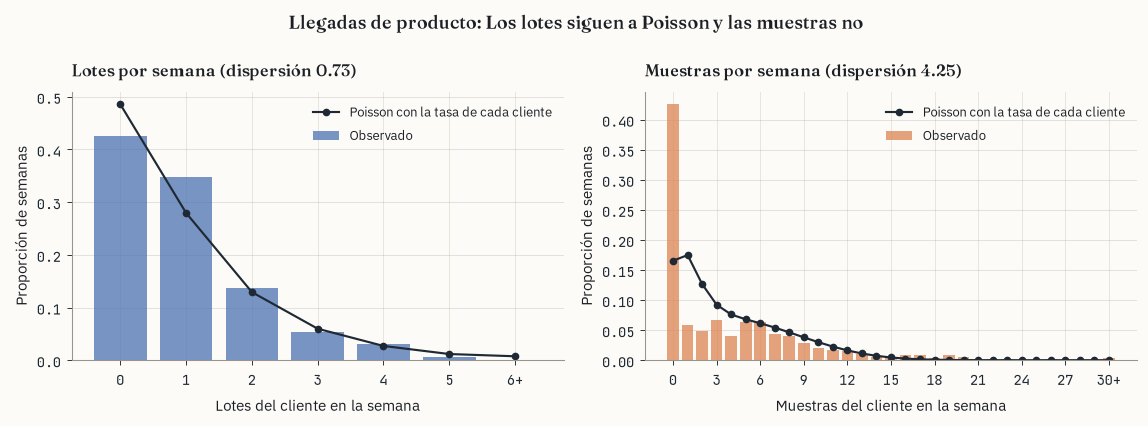

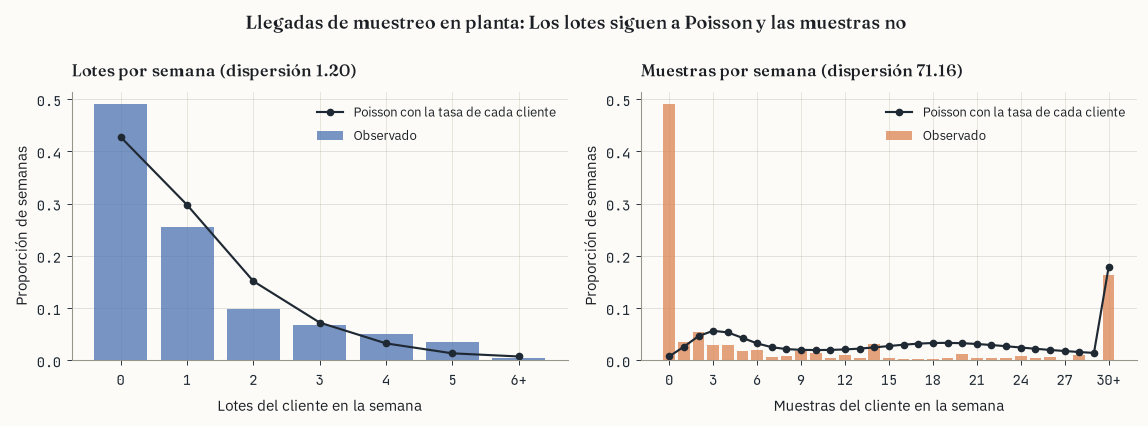

Tipo,Clientes,Índice muestras (mediana),Índice muestras (máximo),Índice lotes (mediana),Muestras sobredispersas,Lotes sobredispersos,Lotes subdispersos,Índice compuesto predicho (mediana)
producto,22,4.25,14.58,0.73,0.95,0.05,0.50,6.00
muestreo en planta,8,71.16,396.43,1.20,1.00,0.25,0.00,59.98


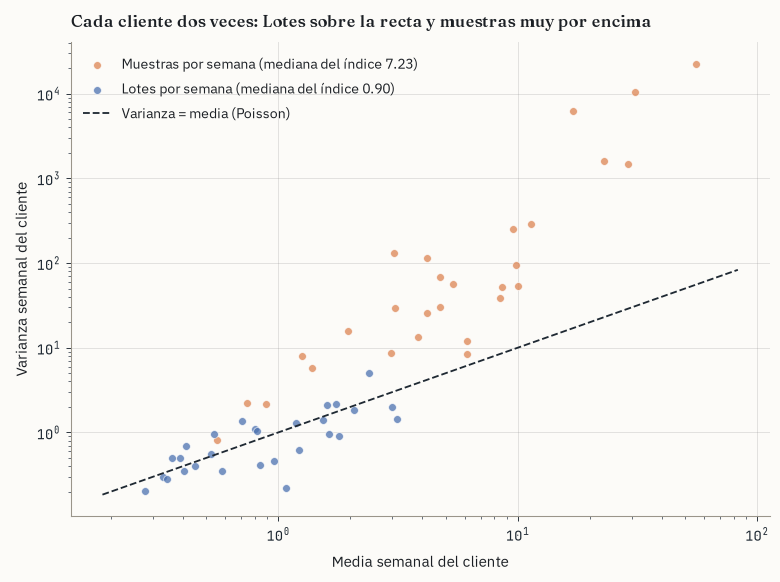

In [3]:
datos_reales.llegadas(c).mostrar()

### 2.2 Por qué las muestras no son Poisson aunque los lotes sí

Si llegan $N$ lotes en la semana y el lote $i$ trae $X_i$ muestras, el total de muestras es una **Poisson
compuesta**:

$$S = \sum_{i=1}^{{\color{#3B64A8}{N}}} {\color{#C46A2B}{X_i}}, \qquad {\color{#3B64A8}{N}} \sim
\mathrm{Poisson}({\color{#3B64A8}{\lambda}})$$

$$E[S] = {\color{#3B64A8}{\lambda}}\, E[{\color{#C46A2B}{X}}], \qquad
\mathrm{Var}[S] = {\color{#3B64A8}{\lambda}}\, E[{\color{#C46A2B}{X}}^2], \qquad
\frac{\mathrm{Var}[S]}{E[S]} = \frac{E[{\color{#C46A2B}{X}}^2]}{E[{\color{#C46A2B}{X}}]}$$

O sea que aunque los lotes sean Poisson el índice de las muestras ya no es 1 sino el cociente entre el segundo
momento y la media del tamaño de lote. Si todos los lotes trajeran una muestra volveríamos a la Poisson y entre más
varíe el tamaño más grande es el índice. Esa es la cuenta que aparece en la segunda nota de arriba y explica por qué
los clientes de planta (con lotes de tamaño muy variable) tienen índices de muestras tan altos.

## 3. Tamaño de los lotes

Si los lotes llegan como Poisson lo que queda por describir es cuántas muestras trae cada uno. Como un lote tiene al
menos una muestra modelamos el tamaño como uno más un conteo y probamos tres opciones: Uno más una Poisson (lo que
hace nuestra simulación), uno más una geométrica (cada muestra adicional llega con la misma probabilidad que la
anterior) y uno más una binomial negativa, que agrega un parámetro $r$ para colas más largas (con $r = 1$ es la
geométrica). Las comparamos con el AIC, que premia el ajuste y castiga cada parámetro adicional (gana el menor).

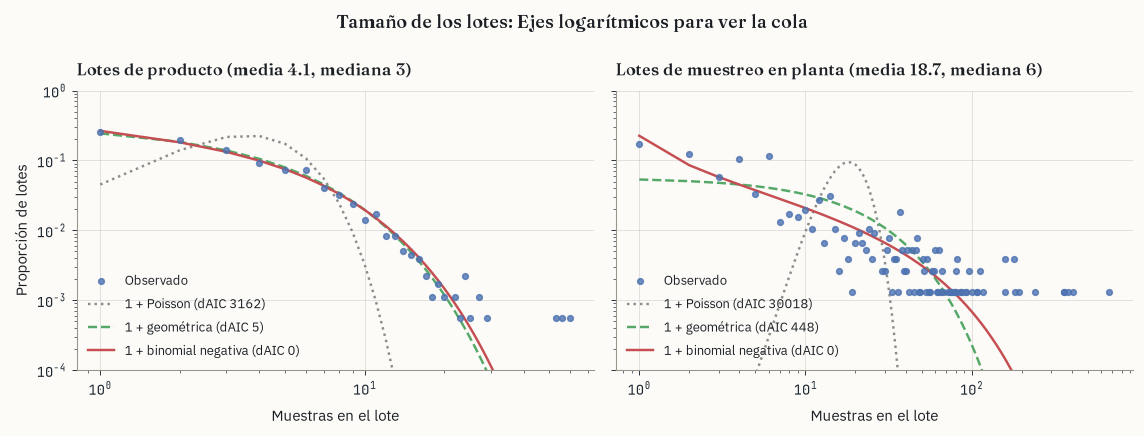

Tipo,Modelo,Parámetros,Media de X menos uno,r,AIC,Diferencia de AIC
producto,1 + Poisson,1,3.10,∞,11266.76,3161.53
producto,1 + geométrica,1,3.10,1.00,8110.64,5.40
producto,1 + binomial negativa,2,3.10,0.88,8105.23,0.00
muestreo en planta,1 + Poisson,1,17.71,∞,35518.93,30018.39
muestreo en planta,1 + geométrica,1,17.71,1.00,5948.19,447.66
muestreo en planta,1 + binomial negativa,2,17.71,0.39,5500.53,0.00


Tipo,Muestras en el lote,Observada,1 + Poisson,1 + geométrica,1 + binomial negativa
producto,1,0.255,0.045,0.244,0.265
producto,2,0.194,0.140,0.185,0.182
producto,3 a 4,0.233,0.441,0.245,0.232
producto,5 a 9,0.242,0.370,0.246,0.235
producto,10 a 19,0.067,0.005,0.076,0.079
producto,20 a 49,0.007,0.000,0.005,0.007
producto,50 o más,0.002,0.000,0.000,0.000
muestreo en planta,1,0.169,0.000,0.053,0.225
muestreo en planta,2,0.122,0.000,0.051,0.086
muestreo en planta,3 a 4,0.163,0.000,0.093,0.103


In [4]:
datos_reales.lotes(c).mostrar()

## 4. Segmentos de clientes

La otra propuesta de Daniel era clasificar a los clientes por su volumen. Usamos el mismo procedimiento de la etapa 05
(K-means con la regla de la silueta y nombres que salen de las variables en que cada grupo más se aparta) pero ahora
con variables que salen de las secciones anteriores: Muestras y lotes por semana, dispersión semanal, proporción de
semanas con envío, tamaño de lote, proporción de muestreo en planta y no conformidad.

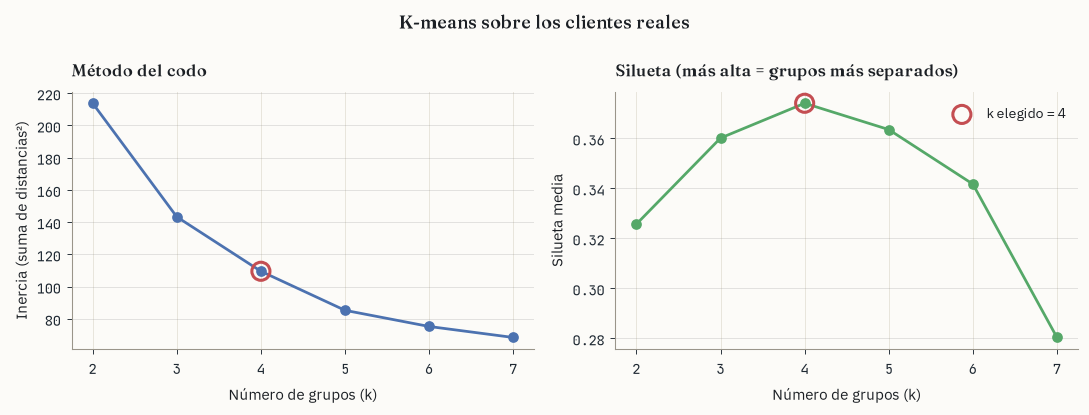

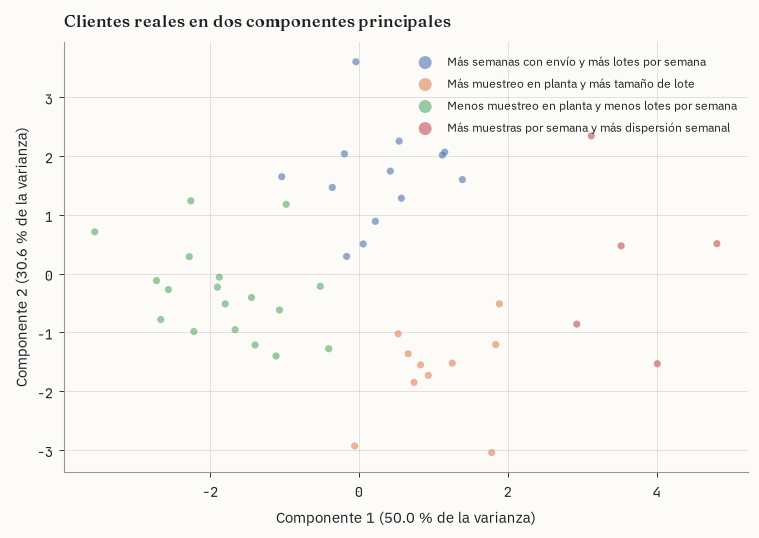

Segmento,Clientes,Proporción de clientes,Proporción de muestras,No conformidad,Variables que lo distinguen
Más semanas con envío y más lotes por semana,13,0.283,0.279,0.028,"semanas con envío +1.1 DE, lotes por semana +0.8 DE"
Más muestreo en planta y más tamaño de lote,10,0.217,0.099,0.037,"muestreo en planta +1.2 DE, tamaño de lote +0.8 DE, semanas con envío -0.8 DE, lotes por semana -0.6 DE"
Menos muestreo en planta y menos lotes por semana,18,0.391,0.060,0.115,"muestreo en planta -0.8 DE, lotes por semana -0.6 DE, semanas con envío -0.6 DE, no conformidad +0.6 DE, muestras por semana -0.6 DE, tamaño de lote -0.5 DE"
Más muestras por semana y más dispersión semanal,5,0.109,0.563,0.032,"muestras por semana +2.4 DE, dispersión semanal +2.3 DE, tamaño de lote +1.5 DE, muestreo en planta +1.2 DE, lotes por semana +1.2 DE, semanas con envío +0.7 DE"


Segmento,muestras por semana,dispersión semanal,semanas con envío,lotes por semana,tamaño de lote,muestreo en planta,no conformidad
Más semanas con envío y más lotes por semana,6.15,6.03,0.81,1.22,5.29,0.15,0.03
Más muestreo en planta y más tamaño de lote,4.40,24.67,0.27,0.39,12.35,0.98,0.02
Menos muestreo en planta y menos lotes por semana,0.96,4.45,0.28,0.30,3.42,0.00,0.11
Más muestras por semana y más dispersión semanal,28.93,344.56,0.68,1.74,23.11,0.99,0.01


In [5]:
datos_reales.segmentos(c).mostrar()

## 5. Riesgo de no conformidad al ingreso

Para no quedarnos solo en la descripción nos preguntamos si la base real deja anticipar qué muestras van a salir no
conformes con lo que se sabe en el momento de recibirlas. Si se pudiera, recepción podría priorizar esas muestras
(revisarlas primero o avisarle al cliente). La **clase 1** es la muestra con dictamen "no cumple" y la clase 0 la
que cumple.

### 5.1 Protocolo y particiones

Antes de comparar modelos fijamos las reglas. Los predictores son los que existen al registrar la muestra: Sector,
origen de la muestra, forma farmacéutica, si el cuadro analítico es complejo, número de especificaciones (lo fija el
cuadro que se asigna al recibirla), tipo de lote, cuántas muestras del mismo lote ya se habían registrado antes y la
historia del cliente. Le dimos varias vueltas a dos fugas. La primera era el tamaño del lote: Antes usábamos el total
de muestras del lote en el día, que solo se sabe cuando el día se cierra. Ahora contamos solo las muestras
del mismo cliente, día y tipo registradas antes que esta. La segunda era la historia del cliente: Solo cuenta los
dictámenes cuya última lectura es anterior al ingreso (y nunca antes del ingreso de esa muestra porque hay lecturas
con fecha mal digitada).

La guía del curso propone como referencia 60 % de entrenamiento, 20 % de validación y 20 % de prueba. Nosotros
mantuvimos los mismos cortes por fecha de todo el proyecto (entrenamiento antes de julio de 2025, validación hasta
diciembre de 2025 y prueba en 2026) porque así el modelo siempre se mide en un periodo posterior al que vio, que es
como se usaría en recepción. La guía permite proporciones distintas si se justifican. Toda la preparación
(imputación, escalado y codificación) vive dentro de una tubería que se ajusta solo con entrenamiento.

In [6]:
datos_reales.riesgo_protocolo(c).mostrar()

Partición,Desde,Hasta,Muestras,Clientes,Muestreo en planta,Sin historia del cliente,No conformidad
Entrenamiento,2024-06-04,2025-06-27,15628,69,0.677,0.035,0.036
Validación,2025-07-01,2025-12-19,5823,57,0.623,0.018,0.041


### 5.2 Modelos y configuraciones

Comparamos cuatro cosas. La **referencia** le da a todas las muestras la probabilidad de entrenamiento y no ordena
nada. La **regla simple** usa como probabilidad la tasa histórica de no conformidad del cliente (encogida hacia la
tasa general cuando tiene poca historia). La **regresión logística** la probamos con tres valores de C, el inverso de
la regularización (con C chico los coeficientes se encogen más). El **árbol de decisión** lo probamos con tres
profundidades.

Como la clase 1 es rara la métrica principal es el **PR-AUC** (el área bajo la curva de precisión y recall), que
dice qué tan limpia sale la lista de alertas cuando se ordena por riesgo. Si el modelo ordenara al azar el PR-AUC
sería la prevalencia así que esa es la vara. Al lado reportamos el ROC-AUC (con la probabilidad de la clase 1) y la
precisión, el recall y el F1 con el umbral de menor costo en validación de cada configuración. La elegida es la de
mayor PR-AUC en validación.

Modelo,Configuración,Partición,Umbral,Precisión,Recall,F1,ROC-AUC,PR-AUC
Referencia,probabilidad de entrenamiento,Entrenamiento,0.95,0.000,0.000,0.000,0.500,0.036
Referencia,probabilidad de entrenamiento,Validación,0.95,0.000,0.000,0.000,0.500,0.041
Regla simple,tasa histórica del cliente,Entrenamiento,0.26,0.000,0.000,0.000,0.778,0.108
Regla simple,tasa histórica del cliente,Validación,0.26,0.588,0.042,0.078,0.673,0.105
Regresión logística,C = 0.01,Entrenamiento,0.61,0.000,0.000,0.000,0.801,0.114
Regresión logística,C = 0.01,Validación,0.61,0.341,0.059,0.100,0.689,0.109
Regresión logística,C = 0.1,Entrenamiento,0.64,0.000,0.000,0.000,0.800,0.117
Regresión logística,C = 0.1,Validación,0.64,0.378,0.059,0.101,0.685,0.106
Regresión logística,C = 1,Entrenamiento,0.56,0.000,0.000,0.000,0.800,0.120
Regresión logística,C = 1,Validación,0.56,0.341,0.059,0.100,0.681,0.105


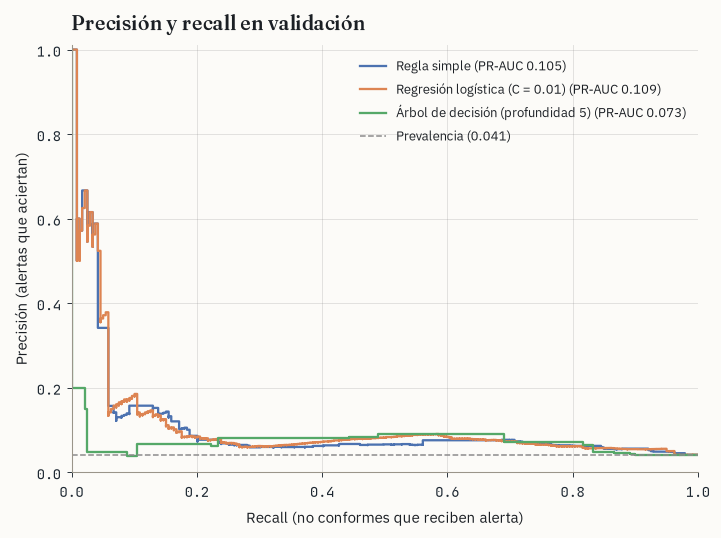

In [7]:
datos_reales.riesgo_modelos(c).mostrar()

### 5.3 Umbral por costo

El modelo entrega una probabilidad y para decidir hay que cortarla en un umbral. No tenemos un costo real de cada
error así que lo declaramos como un **supuesto académico**, el mismo de la etapa 04: Un falso negativo (una muestra no
conforme que no se prioriza) cuesta lo mismo que cinco falsas alarmas. Recorrimos los umbrales en validación, nos
quedamos con el de menor costo y miramos la matriz de confusión con las etiquetas 0 y 1.

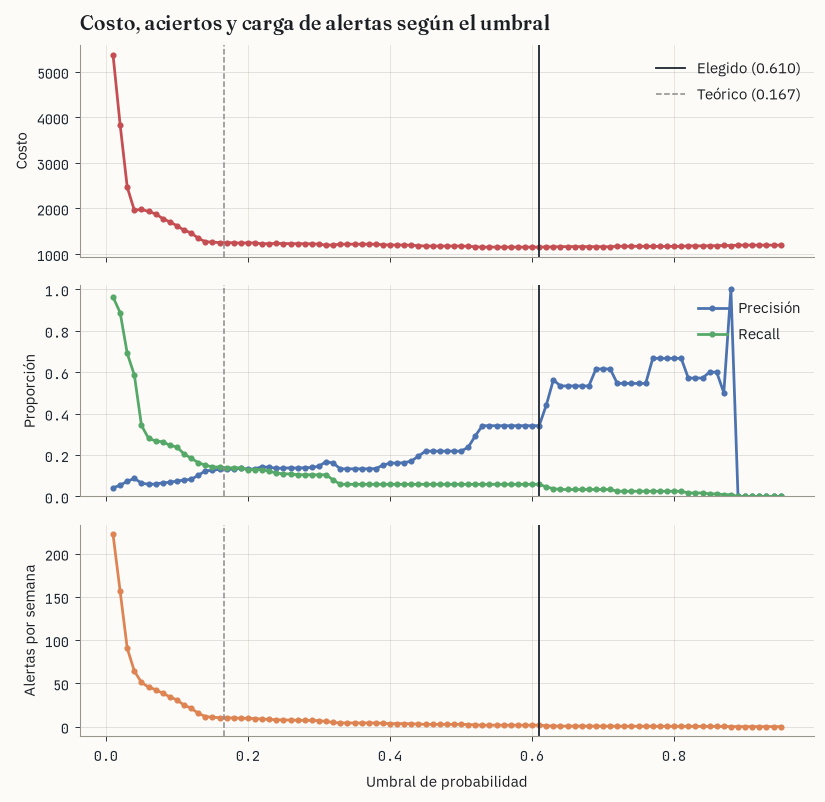

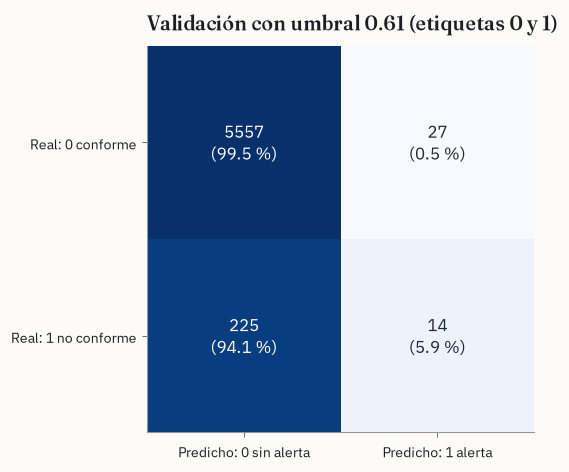

In [8]:
datos_reales.riesgo_umbral(c).mostrar()

### 5.4 Cálculo ilustrativo

Para ver qué hace cada modelo por dentro tomamos la muestra no conforme de validación a la que la regresión
logística le dio más riesgo y rehicimos su probabilidad a mano. El modelo suma un intercepto y cada coeficiente por el
valor de la variable y después pasa ese logit por la sigmoide:

$$z = {\color{#3B64A8}{\beta_0}} + \sum_j {\color{#C46A2B}{\beta_j}}\, x_j, \qquad p = \frac{1}{1 + e^{-z}}$$

En el árbol miramos el primer corte. El índice de Gini de un nodo con una fracción $p$ de no conformes es
$G = 1 - p^2 - (1 - p)^2 = 2p(1 - p)$ y el árbol elige el corte que más baja el promedio de los Gini de los dos hijos,
pesado por cuántas muestras cae en cada uno.

In [9]:
datos_reales.riesgo_calculo(c).mostrar()

Variable,Valor original,Valor en el modelo,Coeficiente,Aporte
Intercepto,,1.000,-3.677,-3.677
tasa_cliente,0.361538,9.580,0.568,5.442
previas_lote,0,-0.535,-0.362,0.194
sector = Farmacéutico,1,1.000,0.119,0.119
origen_muestra = Agua,1,1.000,0.114,0.114
tipo_lote = producto,1,1.000,-0.113,-0.113
forma_farmaceutica = no aplica,1,1.000,-0.092,-0.092
historia_cliente,29,-0.792,-0.102,0.081
n_especificaciones,6,0.322,-0.124,-0.040
cuadro_complejo = False,1,1.000,0.019,0.019


Nodo,Muestras,Fracción no conforme,Gini a mano,Gini del árbol
Raíz (todas),15628,0.0358,0.0690,0.0690
tasa_cliente ≤ 0.0735105,14143,0.0247,0.0481,0.0481
tasa_cliente > 0.0735105,1485,0.1414,0.2428,0.2428


### 5.5 Qué dicen los coeficientes y las reglas

La razón de odds es $e^{\beta}$: Cuánto se multiplican las odds de no conformidad cuando la variable sube en una
unidad (en las numéricas, una desviación estándar) y lo demás se queda igual. En el árbol cada hoja es una regla
que se puede leer en voz alta.

In [10]:
datos_reales.riesgo_interpretacion(c).mostrar()

Variable,Coeficiente,Razón de odds
tasa_cliente,0.568,1.765
previas_lote,-0.362,0.696
sector = Todos,-0.246,0.782
sector = Cosmético,0.175,1.192
origen_muestra = Producto terminado,-0.152,0.859
n_especificaciones,-0.124,0.883
sector = Farmacéutico,0.119,1.126
origen_muestra = Agua,0.114,1.121


Regla,Filas,Fracción de positivos
tasa_cliente > 0.07351 y historia_cliente ≤ 13.5 y historia_cliente > 6,51,0.314
tasa_cliente > 0.07351 y historia_cliente ≤ 13.5 y historia_cliente ≤ 6,50,0.280
tasa_cliente > 0.07351 y historia_cliente > 13.5 y historia_cliente > 108.5 y tasa_cliente ≤ 0.1211 y historia_cliente > 1068,165,0.279
tasa_cliente > 0.07351 y historia_cliente > 13.5 y historia_cliente > 108.5 y tasa_cliente ≤ 0.1211 y historia_cliente ≤ 1068,455,0.178
tasa_cliente > 0.07351 y historia_cliente > 13.5 y historia_cliente ≤ 108.5 y tasa_cliente > 0.176,70,0.171


## 6. Qué tan lejos estaba la simulación

Le dimos varias vueltas a si valía la pena rehacer la base simulada con este hallazgo. Antes de decidir
comparamos pieza por pieza el mecanismo de llegada de la simulación con lo que encontramos en la base real.

In [11]:
datos_reales.comparacion_simulacion(c).mostrar()

Pieza,Simulación,Exportación real
Número de lotes,Poisson por cliente y día con tasa que cambia por semana; los clientes industriales con un número casi fijo por semana,Cerca de Poisson: Índice semanal 0.73 (producto) y 1.20 (planta)
Tamaño del lote,1 + Poisson con tamaño medio de 1.8 a 3.0 según el segmento,"1 + binomial negativa: Media 4.1 (producto) y 18.7 (planta), máximo 675"
Tipos de lote,Uno solo,Producto y planta (66.2 % de las muestras en planta)
Índice de las muestras,E[X²]/E[X] de 2.2 a 3.7,"Mediana 7.23, máximo 407"


## 7. La prueba de 2026

Con el modelo, el umbral y los predictores ya decididos en validación guardamos la decisión completa (con una huella
del modelo para comprobar después que no cambió) y solo entonces abrimos el bloque de 2026. Lo leemos una sola vez y
la lectura queda en el mismo registro de custodia que usa la etapa 06. Ya sabíamos que en 2026 la base cambia
(llegaron clientes nuevos y la no conformidad bajó) así que lo que nos interesa es qué tanto aguanta el modelo ese
cambio y si le gana a la prevalencia y a la regla simple.

Partición,Desde,Hasta,Muestras,Clientes,Muestreo en planta,Sin historia del cliente,No conformidad,Clientes nuevos
Entrenamiento,2024-06-04,2025-06-27,15628,69,0.677,0.035,0.036,
Validación,2025-07-01,2025-12-19,5823,57,0.623,0.018,0.041,
Prueba,2026-01-07,2026-08-31,16325,72,0.671,0.022,0.021,17


Modelo,Umbral,Precisión,Recall,F1,ROC-AUC,IC ROC-AUC,PR-AUC,IC PR-AUC
Referencia (probabilidad de entrenamiento),0.95,0.000,0.000,0.000,0.500,0.500 a 0.500,0.021,0.019 a 0.023
Regla simple (tasa histórica del cliente),0.26,0.115,0.009,0.016,0.761,0.739 a 0.784,0.064,0.053 a 0.081
Regresión logística (C = 0.01),0.61,0.115,0.009,0.016,0.769,0.743 a 0.794,0.072,0.059 a 0.091


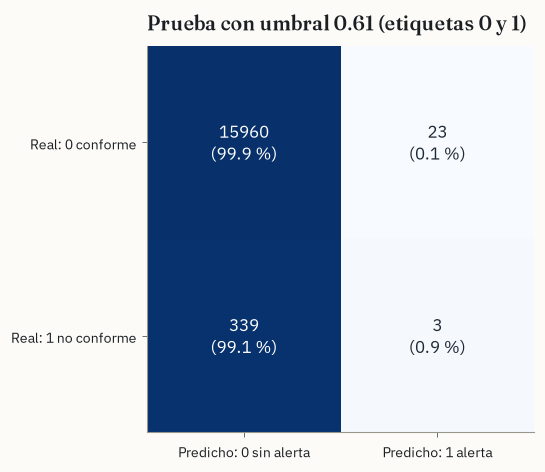

In [12]:
datos_reales.prueba_real(c).mostrar()

## 8. Cierre

In [13]:
datos_reales.cierre(c).mostrar()

← Anterior: [Etapa 01: Datos y exploración](01_datos_exploracion.ipynb)<br>[Notebook completo](Proyecto_Final.ipynb)<br>Siguiente: [Etapa 03: Cribado y regresión](03_cribado_regresion.ipynb) →